--- GWO-MPPT Optimization Results ---
Optimal Duty Cycle  : 0.4319
Maximum Tracked Power: 280.91 W


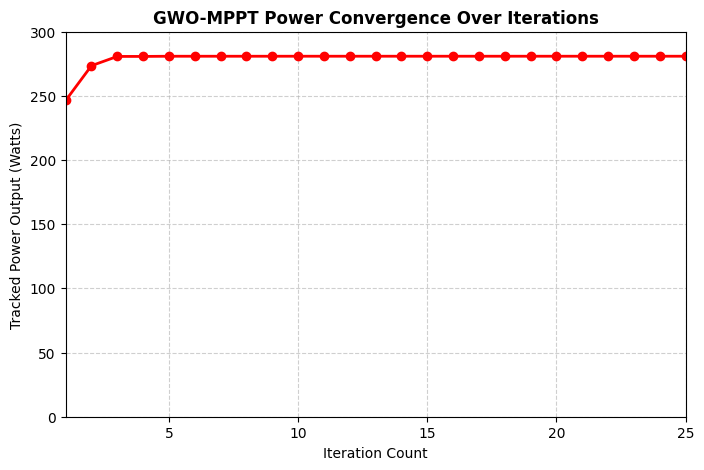

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def measure_pv_power(D, G=1000, T=25):
    """
    Simulates the true non-linear electrical behavior of a solar panel array
    coupled to a standard DC-DC boost converter discharging into a fixed load.
    """
    Voc = 42.0 * (1.0 + 0.001 * (G - 1000) - 0.003 * (T - 25))
    Isc = 9.0 * (G / 1000.0) * (1.0 + 0.0005 * (T - 25))

    V_out = 60.0
    V_pv = V_out * (1.0 - D)

    if V_pv >= Voc or V_pv <= 0:
        return 0.0

    I_pv = Isc * (1.0 - np.exp((V_pv - Voc) / 3.2))
    I_pv = max(0.0, I_pv)

    return V_pv * I_pv

def gwo_mppt_optimization(pack_size=6, max_iter=25, G=1000, T=25):
    D_min, D_max = 0.05, 0.90
    np.random.seed(42)
    wolves = np.random.uniform(D_min, D_max, pack_size)

    X_alpha, P_alpha = 0.0, -float('inf')
    X_beta,  P_beta  = 0.0, -float('inf')
    X_delta, P_delta = 0.0, -float('inf')

    convergence_history = []

    for t in range(max_iter):
        a = 2.0 - t * (2.0 / max_iter)

        for i in range(pack_size):
            wolves[i] = np.clip(wolves[i], D_min, D_max)
            p_out = measure_pv_power(wolves[i], G, T)

            if p_out > P_alpha:
                X_delta, P_delta = X_beta, P_beta
                X_beta, P_beta = X_alpha, P_alpha
                X_alpha, P_alpha = wolves[i], p_out
            elif p_out > P_beta:
                X_delta, P_delta = X_beta, P_beta
                X_beta, P_beta = wolves[i], p_out
            elif p_out > P_delta:
                X_delta, P_delta = wolves[i], p_out

        convergence_history.append(P_alpha)

        for i in range(pack_size):
            # Alpha update
            r1, r2 = np.random.rand(), np.random.rand()
            A1 = 2 * a * r1 - a; C1 = 2 * r2
            X1 = X_alpha - A1 * abs(C1 * X_alpha - wolves[i])

            # Beta update
            r1, r2 = np.random.rand(), np.random.rand()
            A2 = 2 * a * r1 - a; C2 = 2 * r2
            X2 = X_beta - A2 * abs(C2 * X_beta - wolves[i])

            # Delta update
            r1, r2 = np.random.rand(), np.random.rand()
            A3 = 2 * a * r1 - a; C3 = 2 * r2
            X3 = X_delta - A3 * abs(C3 * X_delta - wolves[i])

            wolves[i] = (X1 + X2 + X3) / 3.0

    return X_alpha, P_alpha, convergence_history

if __name__ == "__main__":
    G_env = 1000
    T_env = 25

    best_d, max_power, curve = gwo_mppt_optimization(pack_size=6, max_iter=25, G=G_env, T=T_env)

    print("--- GWO-MPPT Optimization Results ---")
    print(f"Optimal Duty Cycle  : {best_d:.4f}")
    print(f"Maximum Tracked Power: {max_power:.2f} W")

    # --- GRAPH GENERATION CODE ---
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(curve) + 1), curve, color='red', marker='o', linewidth=2)
    plt.title("GWO-MPPT Power Convergence Over Iterations", fontsize=12, fontweight='bold')
    plt.xlabel("Iteration Count", fontsize=10)
    plt.ylabel("Tracked Power Output (Watts)", fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xlim(1, 25)
    plt.ylim(0, 300)

    # Show the interactive plot window
    plt.show()
